# Exploratory Data Analysis (EDA)
## COM747 — Data Science and Machine Learning CW2
**Research title:** A Machine Learning Framework for Detecting Multidimensional Care-Intensity Discordance and Predicting 30-Day Hospital Readmission in Patients with Diabetes.

**Dataset:** [UCI Diabetes 130-US Hospitals for Years 1999–2008](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008).

**RQ1:** How is care-intensity discordance associated with 30-day hospital readmission after accounting for patient characteristics and recorded clinical complexity?

**RQ2:** Can care-intensity discordance features improve readmission prediction compared with conventional ML models using patient characteristics and observed care variables?

This notebook consolidates the original six plots and the expanded initial EDA. It covers CRISP-DM data understanding, not final cleaning, feature engineering or modelling. Each row is a hospital encounter; a patient may appear more than once. The raw dataset is not modified on disk.

**How to run:** Place this file in `eda/`, put `diabetic_data.csv` in the parent project's `data/raw/` folder, follow the parent README, select **Python (DSML CW2)** as the notebook kernel, then restart and run all cells. The loader works from the project root or `eda/` and also checks for a local CSV. Do not create another virtual environment.

**Analysis boundary:** Full-dataset EDA here is descriptive only. Before model-directed exploration, define the eligible discharge cohort and reserve a patient-grouped test set; fit all transformations and expected-care models using training data only. These plots do not establish causation or appropriate clinical treatment. The dataset is historical and recorded readmissions may not capture every subsequent admission.

## Phase 1 — Initial data understanding

### 1. Import required libraries

Set the visualisation style and verify the shared kernel.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())

Python executable: /Users/monishachandrashekar/Desktop/DS&ML-CW2 /.venv/bin/python
Working directory: /Users/monishachandrashekar/Desktop/DS&ML-CW2 /Data-science-and-Machine-Learning-Course-work/EDA


### 2. Import the dataset

Preserve literal `None` test-result labels (test not performed) and convert `?` and empty fields to missing values. `df_raw` is the imported source snapshot; `df` is a working copy.

In [2]:
candidates = [
    Path("../data/raw/diabetic_data.csv"),
    Path("data/raw/diabetic_data.csv"),
    Path("diabetic_data.csv"),
    Path("../diabetic_data.csv"),
]
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "Place diabetic_data.csv in the project data/raw/ directory. "
        f"Current working directory: {Path.cwd()}"
    )

df_raw = pd.read_csv(data_path, keep_default_na=False, na_values=["?", ""])
df = df_raw.copy()
print("Loaded:", data_path.resolve())
display(df.head())

Loaded: /Users/monishachandrashekar/Desktop/DS&ML-CW2 /Data-science-and-Machine-Learning-Course-work/data/raw/diabetic_data.csv


/var/folders/2m/b7dfp3r133v8frt6g9kbg0v80000gn/T/ipykernel_5658/4214563334.py:14: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(data_path, keep_default_na=False, na_values=["?", ""])


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


### 3. Initial dataset inspection

Inspect the dimensions, data types and unique patient counts.

In [3]:
print("Number of hospital encounters:", len(df))
print("Number of columns:", df.shape[1])
print("Number of unique patients:", df["patient_nbr"].nunique())
print("\nDataset information:")
df.info()
print("\nColumn names:", df.columns.tolist())

Number of hospital encounters: 101766
Number of columns: 50
Number of unique patients: 71518

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures      

### 4. Descriptive statistics

Summarise numeric and categorical variables. Identifiers are excluded from numeric summaries because their magnitudes have no clinical meaning.

In [4]:
display(df.drop(columns=["encounter_id", "patient_nbr"]).describe().T)
display(df.describe(include=["object", "category", "string"]).T)

,count,mean,std,min,25%,50%,75%,max
admission_type_id,101766.0,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0


,count,unique,top,freq
race,99493,5,Caucasian,76099
gender,101766,3,Female,54708
age,101766,10,[70-80),26068
weight,3197,9,[75-100),1336
payer_code,61510,17,MC,32439
medical_specialty,51817,72,InternalMedicine,14635
diag_1,101745,716,428,6862
diag_2,101408,748,276,6752
diag_3,100343,789,250,11555
max_glu_serum,101766,4,None,96420


### 5. Missing-value analysis

Quantify missing data. Literal `None` in `A1Cresult` and `max_glu_serum` is kept separate from missing values.

,Missing Count,Missing Percentage
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


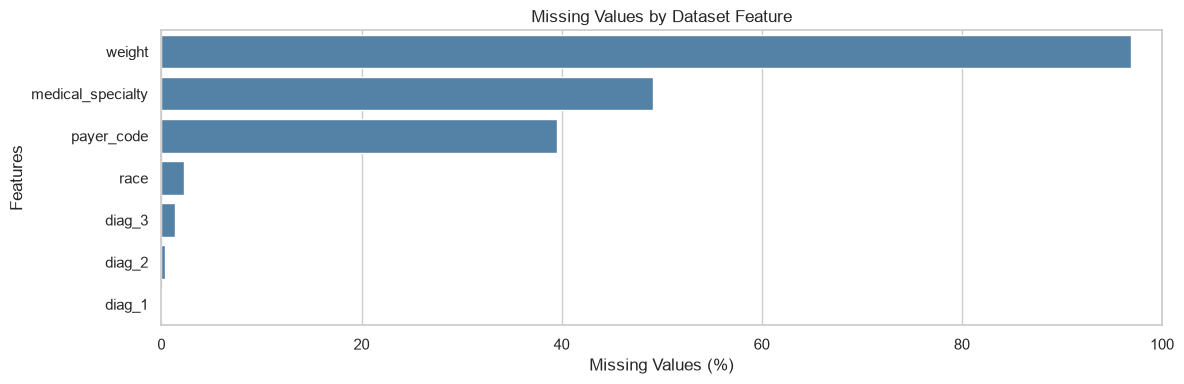

In [5]:
missing_values = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100,
})
missing_values = missing_values.loc[missing_values["Missing Count"] > 0].sort_values(
    "Missing Percentage", ascending=False
)
display(missing_values.round(2))

if not missing_values.empty:
    plt.figure(figsize=(12, max(4, len(missing_values) * 0.45)))
    sns.barplot(data=missing_values.rename_axis("Feature").reset_index(),
                x="Missing Percentage", y="Feature", color="steelblue")
    plt.title("Missing Values by Dataset Feature")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Features")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected under the current import rules.")

### 6. Duplicate records and repeated patients

Repeated patient encounters are not necessarily duplicate records. Patient identifiers will be needed for grouped splitting but should not be used as predictors.

In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate encounter IDs:", df["encounter_id"].duplicated().sum())
print("Patients with multiple encounters:", (df["patient_nbr"].value_counts() > 1).sum())

Duplicate rows: 0
Duplicate encounter IDs: 0
Patients with multiple encounters: 16773


## Phase 2 — Demographic analysis

### 7. Hospital encounter distribution by age

Original EDA plot 1: identify the age groups most represented in the dataset.

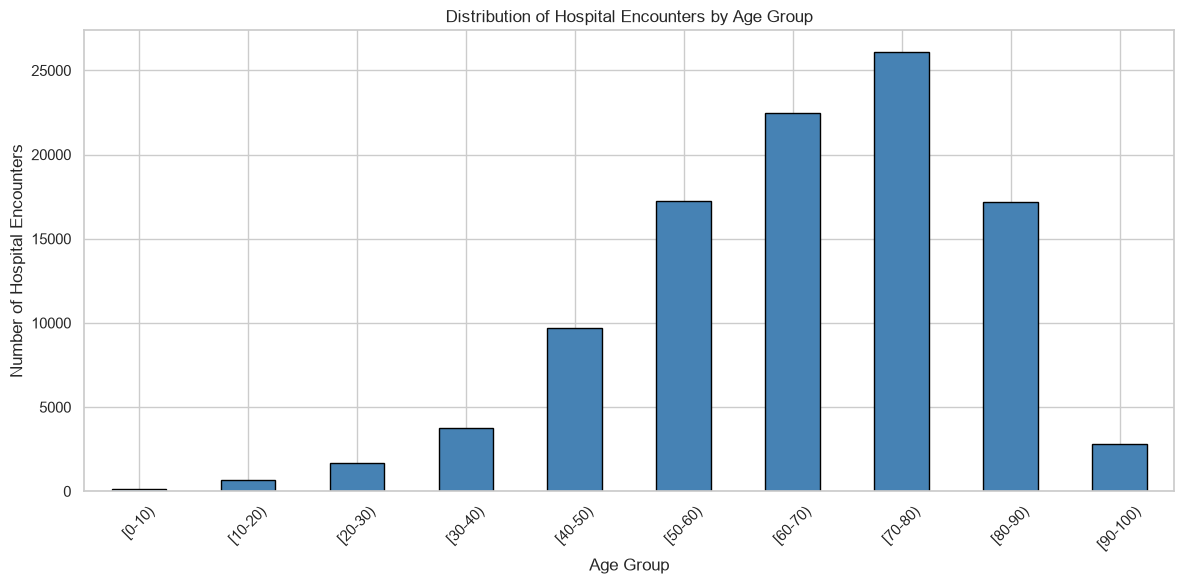

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

In [7]:
age_counts = df["age"].value_counts().sort_index()
plt.figure(figsize=(12, 6))
age_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Distribution of Hospital Encounters by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Hospital Encounters")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(age_counts)

### 8. Gender distribution

Original EDA plot 2: summarise recorded gender by encounter.

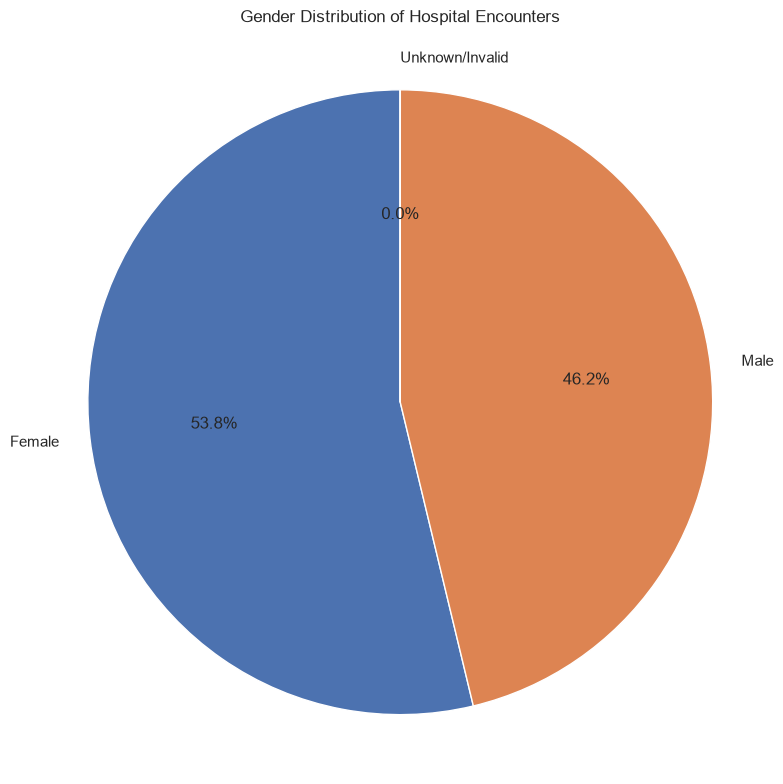

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

In [8]:
gender_counts = df["gender"].fillna("Missing / Unrecorded").value_counts()
plt.figure(figsize=(8, 8))
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%",
        startangle=90, wedgeprops={"edgecolor": "white"})
plt.title("Gender Distribution of Hospital Encounters")
plt.axis("equal")
plt.tight_layout()
plt.show()
display(gender_counts)

### 9. Racial distribution

Support later equality, diversity and inclusion analysis. Preserve missing race as an explicit descriptive group.

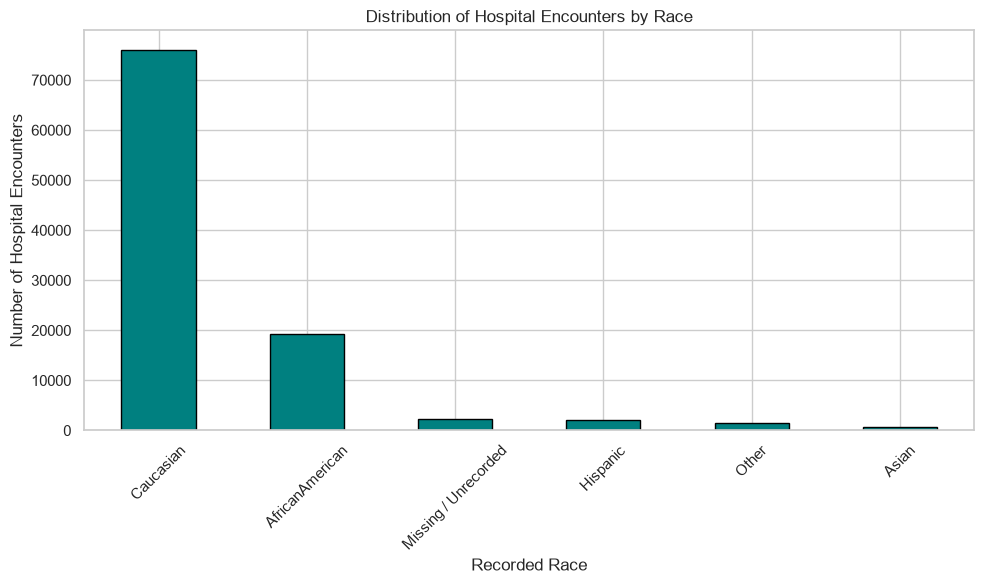

race
Caucasian               76099
AfricanAmerican         19210
Missing / Unrecorded     2273
Hispanic                 2037
Other                    1506
Asian                     641
Name: count, dtype: int64

In [9]:
race_counts = df["race"].fillna("Missing / Unrecorded").value_counts()
plt.figure(figsize=(10, 6))
race_counts.plot(kind="bar", color="teal", edgecolor="black")
plt.title("Distribution of Hospital Encounters by Race")
plt.xlabel("Recorded Race")
plt.ylabel("Number of Hospital Encounters")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(race_counts)

## Phase 3 — Readmission analysis

### 10. Hospital readmission distribution

Original EDA plot 3. The original categories are `NO` (no recorded readmission), `>30` (later readmission) and `<30` (early readmission). The research uses the original `<30` label as its operational 30-day outcome.

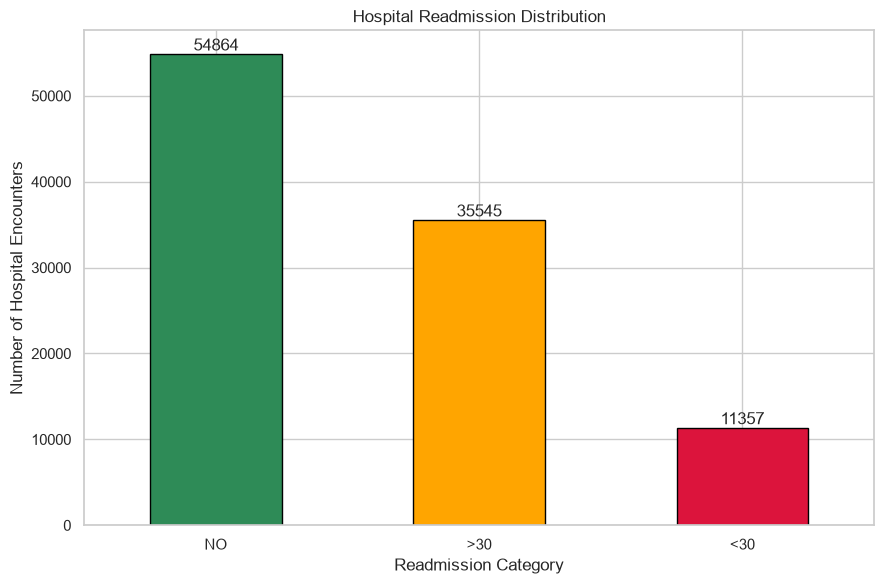

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [10]:
readmission_order = ["NO", ">30", "<30"]
assert df["readmitted"].isin(readmission_order).all(), "Unexpected or missing readmission labels"
readmission_counts = df["readmitted"].value_counts().reindex(readmission_order, fill_value=0)
plt.figure(figsize=(9, 6))
ax = readmission_counts.plot(kind="bar", color=["seagreen", "orange", "crimson"], edgecolor="black")
ax.bar_label(ax.containers[0])
plt.title("Hospital Readmission Distribution")
plt.xlabel("Readmission Category")
plt.ylabel("Number of Hospital Encounters")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(readmission_counts)

### 11. Readmission percentage distribution

Original EDA plot 5: show proportions of the three original categories.

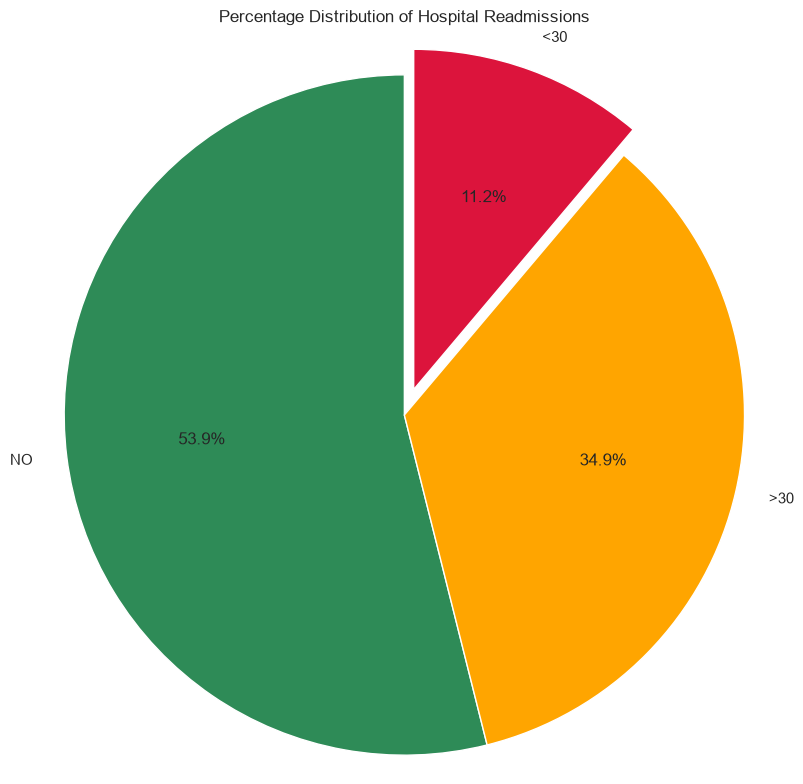

In [11]:
plt.figure(figsize=(8, 8))
plt.pie(readmission_counts, labels=readmission_counts.index, autopct="%1.1f%%",
        startangle=90, colors=["seagreen", "orange", "crimson"], explode=[0, 0, 0.08])
plt.title("Percentage Distribution of Hospital Readmissions")
plt.axis("equal")
plt.tight_layout()
plt.show()

### 12. Binary research target and class imbalance

Map `<30` to 1 and both other valid categories to 0 for descriptive analysis. This is not yet the final modelling cohort. Never use either readmission label as an input feature.

,Encounters,Percentage
readmitted_30,,
0,90409,88.84
1,11357,11.16


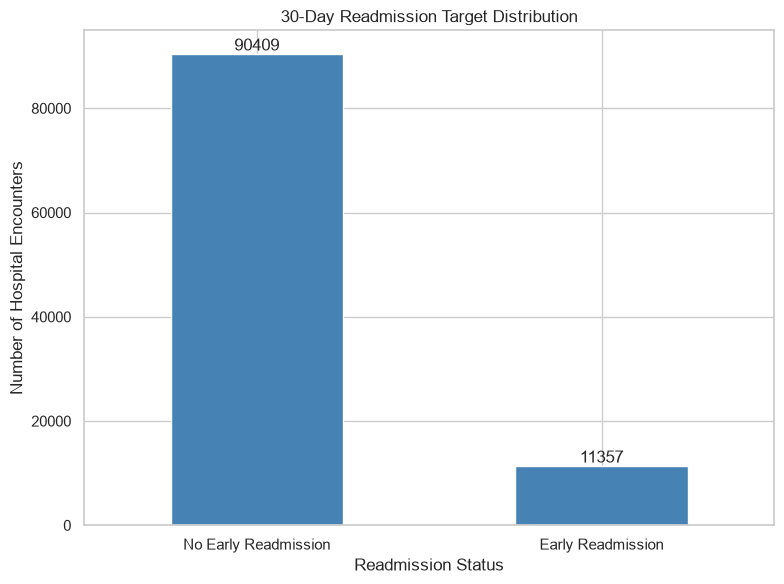

In [12]:
df["readmitted_30"] = df["readmitted"].map({"<30": 1, ">30": 0, "NO": 0}).astype(int)
counts = df["readmitted_30"].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({"Encounters": counts, "Percentage": counts / len(df) * 100}).round(2))
plt.figure(figsize=(8, 6))
ax = counts.plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("30-Day Readmission Target Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Hospital Encounters")
plt.xticks([0, 1], ["No Early Readmission", "Early Readmission"], rotation=0)
plt.tight_layout()
plt.show()

### 13. Readmission percentage by age group

Original EDA plot 6: percentages are calculated within each age group, not across the whole dataset.

readmitted,NO,>30,<30
age,,,
[0-10),81.99,16.15,1.86
[10-20),61.79,32.42,5.79
[20-30),54.98,30.78,14.24
[30-40),57.32,31.44,11.23
[40-50),55.55,33.85,10.60
[50-60),56.04,34.29,9.67
[60-70),53.75,35.12,11.13
[70-80),51.88,36.35,11.77
[80-90),51.73,36.19,12.08


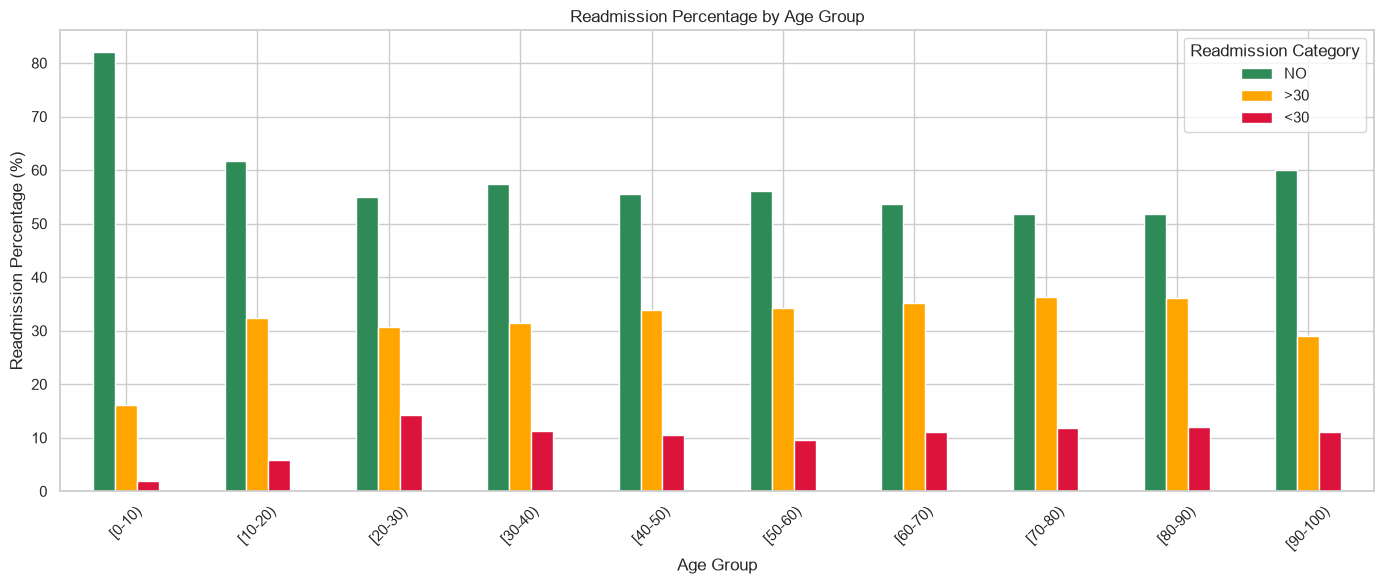

In [13]:
age_readmission = pd.crosstab(df["age"], df["readmitted"], normalize="index").reindex(
    columns=readmission_order, fill_value=0) * 100
display(age_readmission.round(2))
age_readmission.plot(kind="bar", figsize=(14, 6), color=["seagreen", "orange", "crimson"])
plt.title("Readmission Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Readmission Category")
plt.tight_layout()
plt.show()

### 14. 30-day readmission by demographic groups

Compare within-group rates and denominators. Small groups can have unstable rates; these descriptive differences are not evidence of model unfairness.


30-Day Readmission by age


,Encounters,Early_Readmissions,Readmission Rate (%)
age,,,
[0-10),161,3,1.86
[10-20),691,40,5.79
[20-30),1657,236,14.24
[30-40),3775,424,11.23
[40-50),9685,1027,10.60
[50-60),17256,1668,9.67
[60-70),22483,2502,11.13
[70-80),26068,3069,11.77
[80-90),17197,2078,12.08


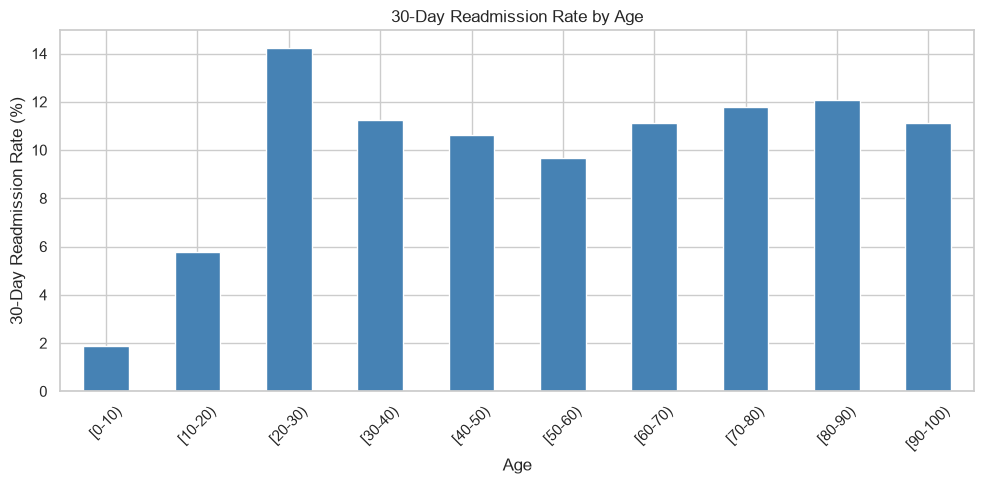


30-Day Readmission by gender


,Encounters,Early_Readmissions,Readmission Rate (%)
gender,,,
Female,54708,6152,11.25
Male,47055,5205,11.06
Unknown/Invalid,3,0,0.00


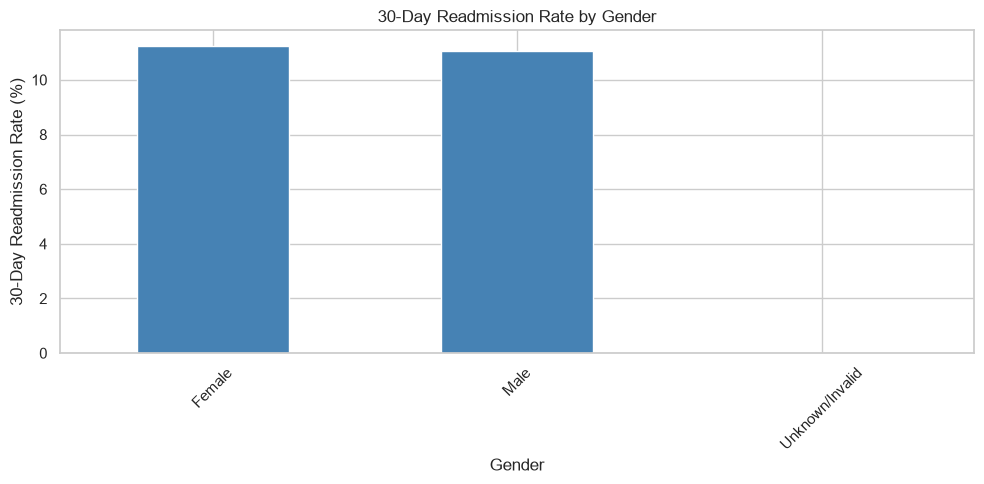


30-Day Readmission by race


,Encounters,Early_Readmissions,Readmission Rate (%)
race,,,
AfricanAmerican,19210,2155,11.22
Asian,641,65,10.14
Caucasian,76099,8592,11.29
Hispanic,2037,212,10.41
Missing / Unrecorded,2273,188,8.27
Other,1506,145,9.63


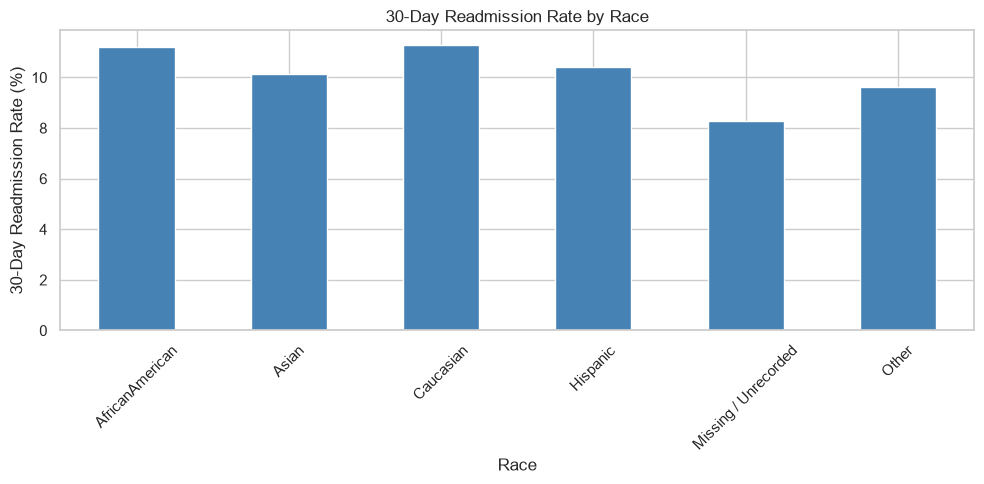

In [14]:
for feature in ["age", "gender", "race"]:
    group_labels = df[feature].fillna("Missing / Unrecorded")
    summary = df.groupby(group_labels)["readmitted_30"].agg(
        Encounters="count", Early_Readmissions="sum", Rate="mean")
    summary["Rate"] *= 100
    summary = summary.rename(columns={"Rate": "Readmission Rate (%)"})
    print(f"\n30-Day Readmission by {feature}")
    display(summary.round(2))
    summary["Readmission Rate (%)"].plot(kind="bar", figsize=(10, 5), color="steelblue")
    plt.title(f"30-Day Readmission Rate by {feature.title()}")
    plt.xlabel(feature.title())
    plt.ylabel("30-Day Readmission Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Phase 4 — Care-intensity analysis

The four recorded care dimensions are the proposed regression targets for expected-care estimation. At this stage we only describe observed care; no discordance score is calculated yet.

### 15. Identify the four care-intensity dimensions

Hospital stay (days), laboratory procedures, non-laboratory procedures and number of distinct medications administered.

In [15]:
care_features = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications"]
care_labels = {
    "time_in_hospital": "Hospital Stay Duration",
    "num_lab_procedures": "Laboratory Procedures",
    "num_procedures": "Medical Procedures",
    "num_medications": "Medication Count",
}
display(df[care_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0


### 16. Hospital stay duration distribution

Original EDA plot 4: frequency of recorded inpatient days.

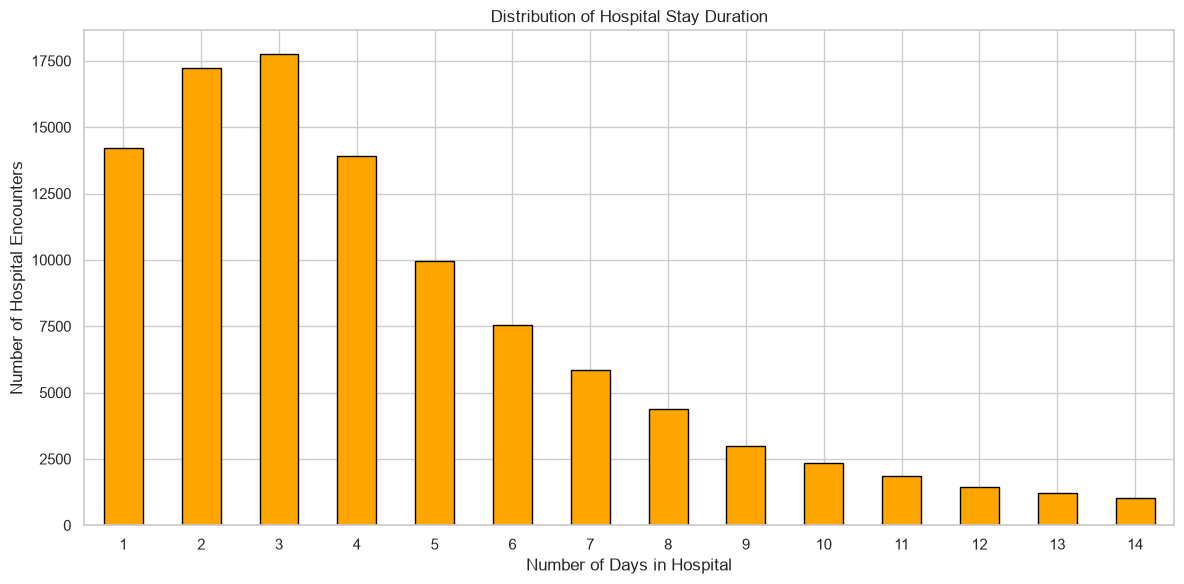

In [16]:
stay_counts = df["time_in_hospital"].value_counts().sort_index()
plt.figure(figsize=(12, 6))
stay_counts.plot(kind="bar", color="orange", edgecolor="black")
plt.title("Distribution of Hospital Stay Duration")
plt.xlabel("Number of Days in Hospital")
plt.ylabel("Number of Hospital Encounters")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 17. Distribution of all four care-intensity variables

Explore variability and skewness.

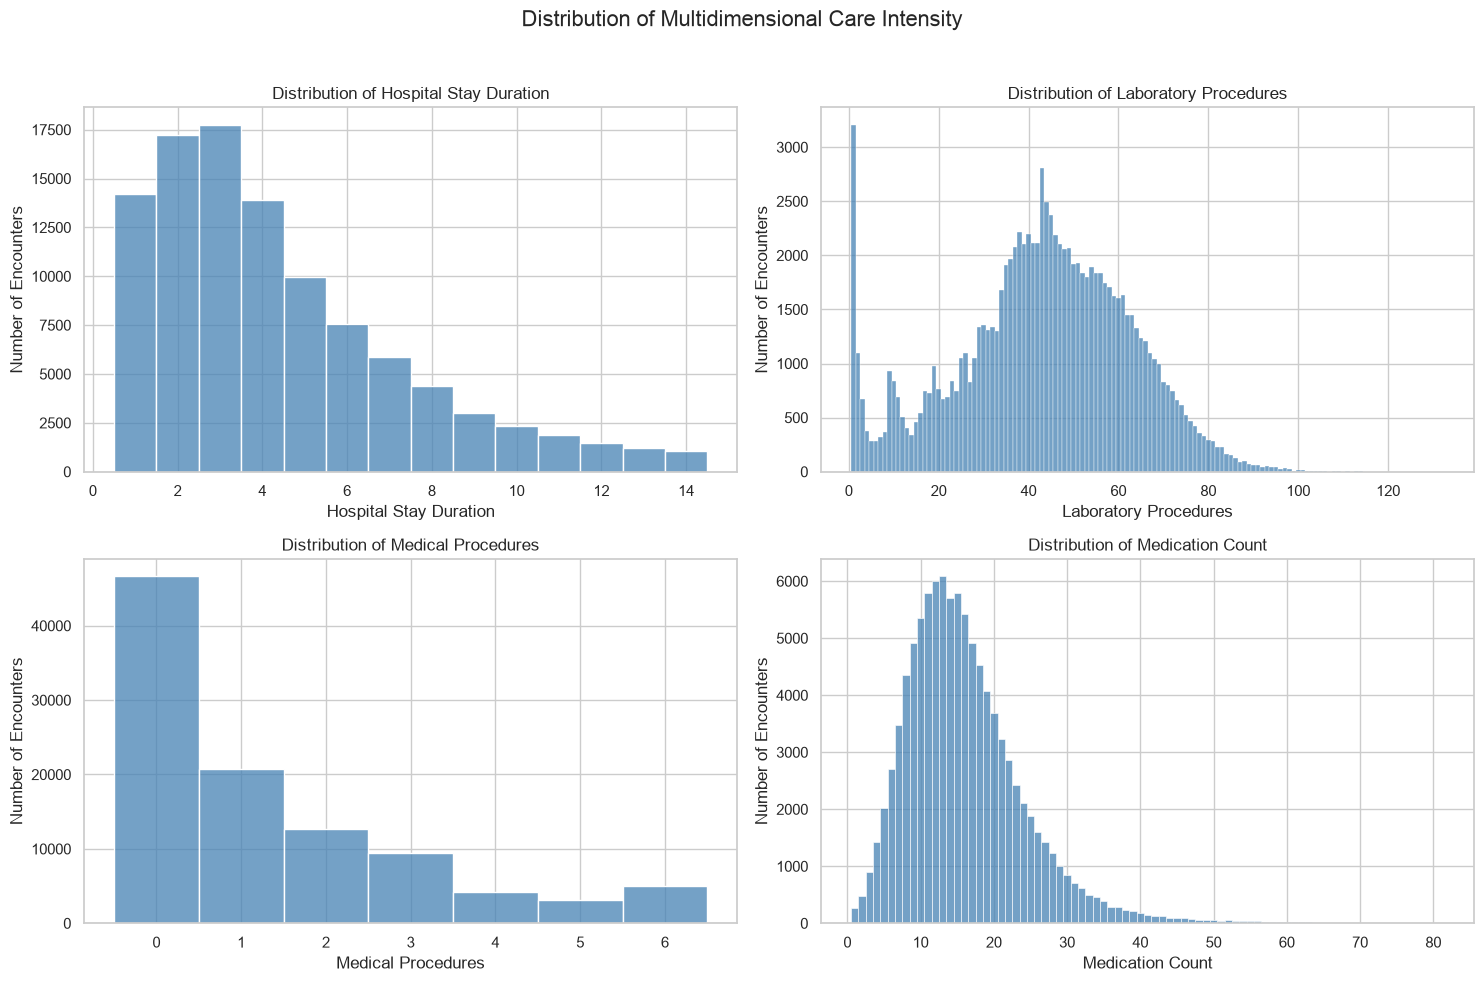

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, feature in zip(axes.flat, care_features):
    sns.histplot(data=df, x=feature, discrete=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {care_labels[feature]}")
    ax.set_xlabel(care_labels[feature])
    ax.set_ylabel("Number of Encounters")
fig.suptitle("Distribution of Multidimensional Care Intensity", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 18. Outlier exploration using boxplots

Unusual care patterns may be important. Do not automatically remove valid extreme values.

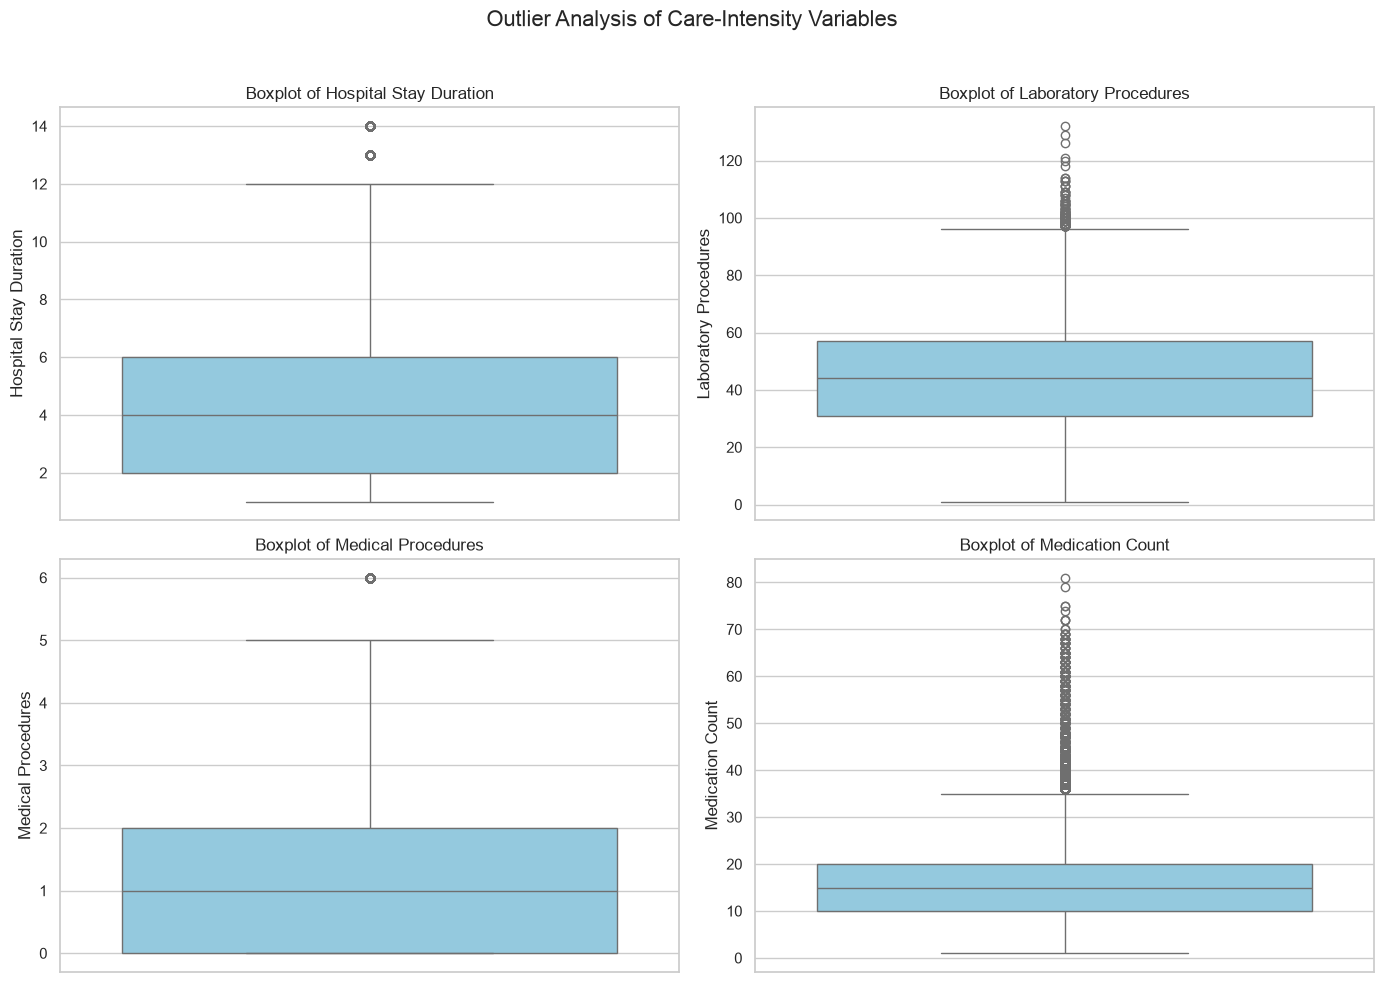

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feature in zip(axes.flat, care_features):
    sns.boxplot(data=df, y=feature, ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {care_labels[feature]}")
    ax.set_ylabel(care_labels[feature])
fig.suptitle("Outlier Analysis of Care-Intensity Variables", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 19. Care intensity versus 30-day readmission

Unadjusted comparisons provide context for RQ1 but do not establish a relationship independent of clinical complexity.

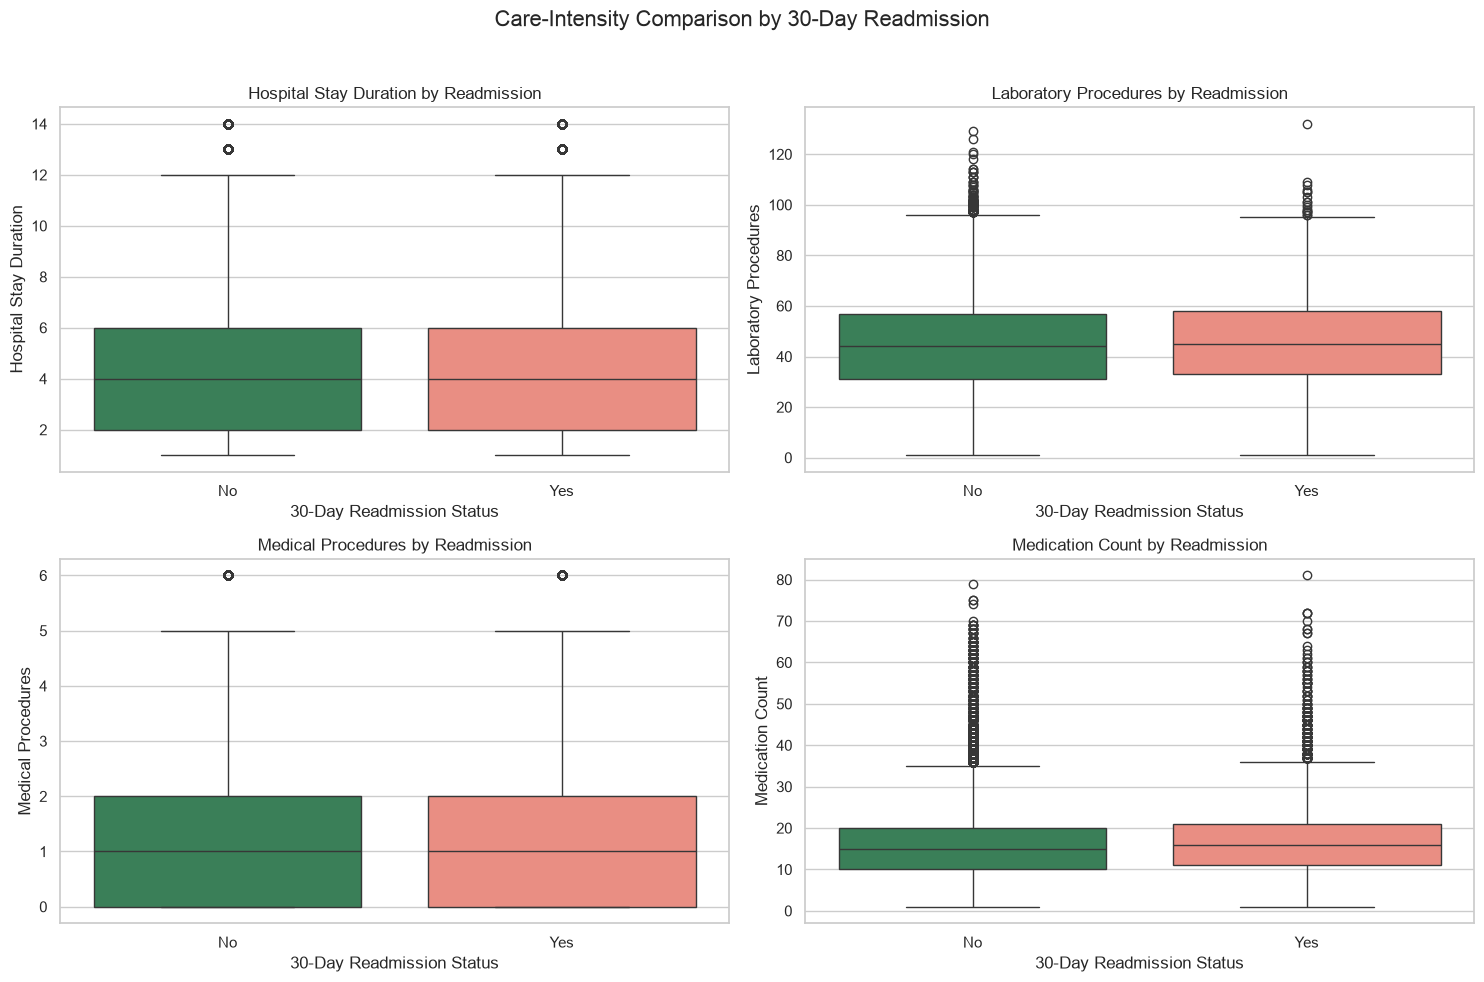

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, feature in zip(axes.flat, care_features):
    sns.boxplot(data=df, x="readmitted_30", y=feature, order=[0, 1],
                hue="readmitted_30", hue_order=[0, 1], palette=["seagreen", "salmon"],
                dodge=False, legend=False, ax=ax)
    ax.set_title(f"{care_labels[feature]} by Readmission")
    ax.set_xlabel("30-Day Readmission Status")
    ax.set_ylabel(care_labels[feature])
    ax.set_xticks([0, 1], ["No", "Yes"])
fig.suptitle("Care-Intensity Comparison by 30-Day Readmission", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 20. Statistical summary of care intensity by readmission

Report count, mean, median and standard deviation to complement the plots.

In [20]:
care_summary = df.groupby("readmitted_30")[care_features].agg(["count", "mean", "median", "std"])
display(care_summary.round(2))

time_in_hospital                    num_lab_procedures         \
                         count  mean median   std              count   mean   
readmitted_30                                                                 
0                        90409  4.35    4.0  2.98              90409  42.95   
1                        11357  4.77    4.0  3.03              11357  44.23   

                            num_procedures                    num_medications  \
              median    std          count  mean median   std           count   
readmitted_30                                                                   
0               44.0  19.72          90409  1.35    1.0  1.71           90409   
1               45.0  19.28          11357  1.28    1.0  1.64           11357   

                                   
                mean median   std  
readmitted_30                      
0              15.91   15.0  8.12  
1              16.90   16.0  8.10

### 21. Readmission rate by hospital stay duration

Show group sizes alongside the rate to help interpret less common stay lengths.

,Encounters,Early_Readmissions,Readmission Rate (%)
time_in_hospital,,,
1,14208,1162,8.18
2,17224,1712,9.94
3,17756,1894,10.67
4,13924,1644,11.81
5,9966,1199,12.03
6,7539,949,12.59
7,5859,752,12.83
8,4391,625,14.23
9,3002,412,13.72


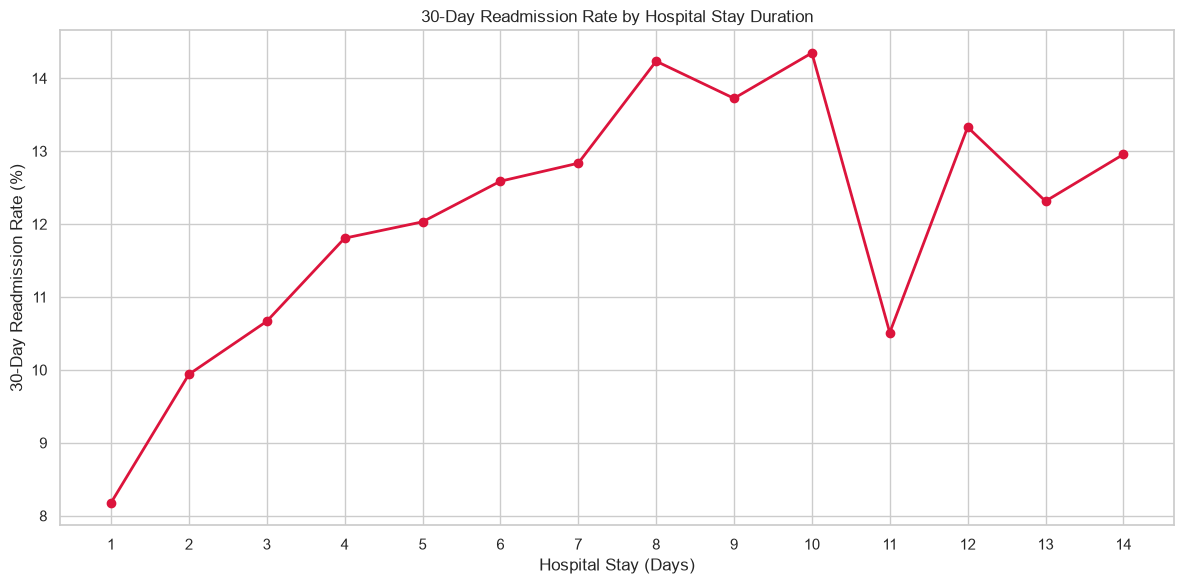

In [21]:
stay_readmission = df.groupby("time_in_hospital")["readmitted_30"].agg(
    Encounters="count", Early_Readmissions="sum", Rate="mean")
stay_readmission["Rate"] *= 100
stay_readmission = stay_readmission.rename(columns={"Rate": "Readmission Rate (%)"})
display(stay_readmission.round(2))
plt.figure(figsize=(12, 6))
plt.plot(stay_readmission.index, stay_readmission["Readmission Rate (%)"], marker="o", linewidth=2, color="crimson")
plt.title("30-Day Readmission Rate by Hospital Stay Duration")
plt.xlabel("Hospital Stay (Days)")
plt.ylabel("30-Day Readmission Rate (%)")
plt.xticks(stay_readmission.index)
plt.tight_layout()
plt.show()

## Phase 5 — Clinical complexity and previous healthcare utilisation

Recorded diagnosis counts are imperfect proxies for clinical complexity, and may depend on care received during the encounter. They are not verified admission-time severity measures.

### 22. Clinical complexity and utilisation statistics

Inspect recorded diagnosis count and prior-year inpatient, outpatient and emergency utilisation.

In [22]:
clinical_features = ["number_diagnoses", "number_inpatient", "number_outpatient", "number_emergency"]
display(df[clinical_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0


### 23. Distribution of clinical complexity and utilisation

Identify skewness and concentrations at zero.

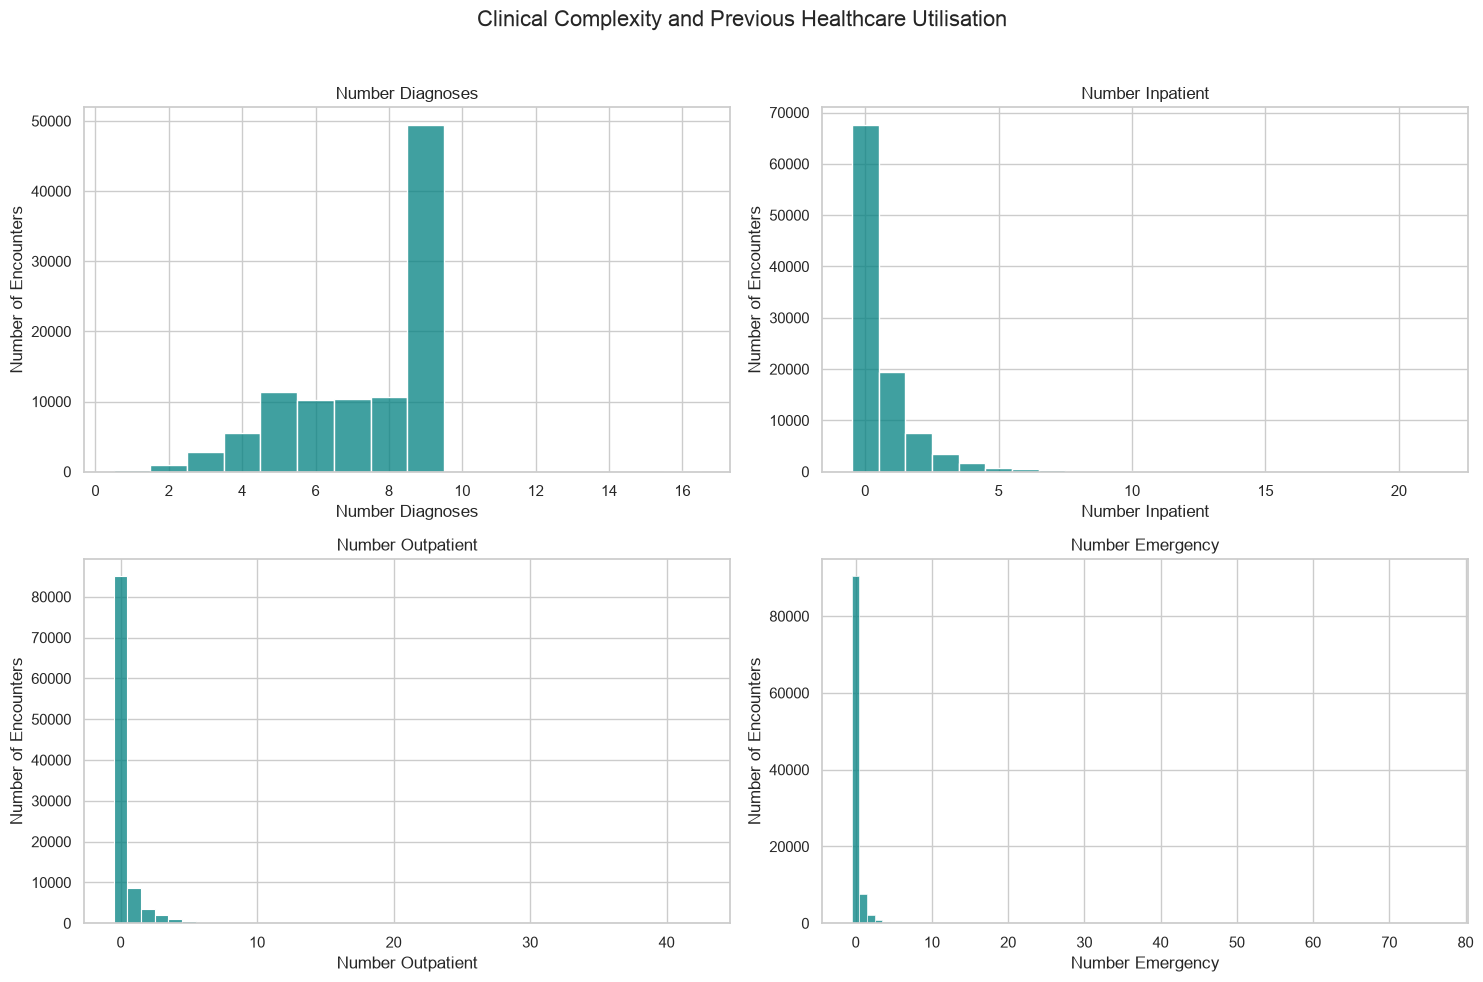

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, feature in zip(axes.flat, clinical_features):
    sns.histplot(data=df, x=feature, discrete=True, ax=ax, color="teal")
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel(feature.replace("_", " ").title())
    ax.set_ylabel("Number of Encounters")
fig.suptitle("Clinical Complexity and Previous Healthcare Utilisation", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 24. Care intensity by recorded clinical complexity

Compare median observed care across recorded diagnosis counts. This is not yet a fitted expected-care benchmark.

,time_in_hospital,num_lab_procedures,num_procedures,num_medications
number_diagnoses,,,,
1,2.0,45.0,0.0,5.0
2,2.0,38.0,0.0,8.0
3,2.0,38.0,0.0,10.0
4,3.0,39.0,1.0,11.0
5,3.0,42.0,1.0,12.0
6,3.0,42.0,1.0,13.0
7,3.0,42.0,1.0,14.0
8,4.0,43.0,1.0,15.0
9,4.0,48.0,1.0,17.0


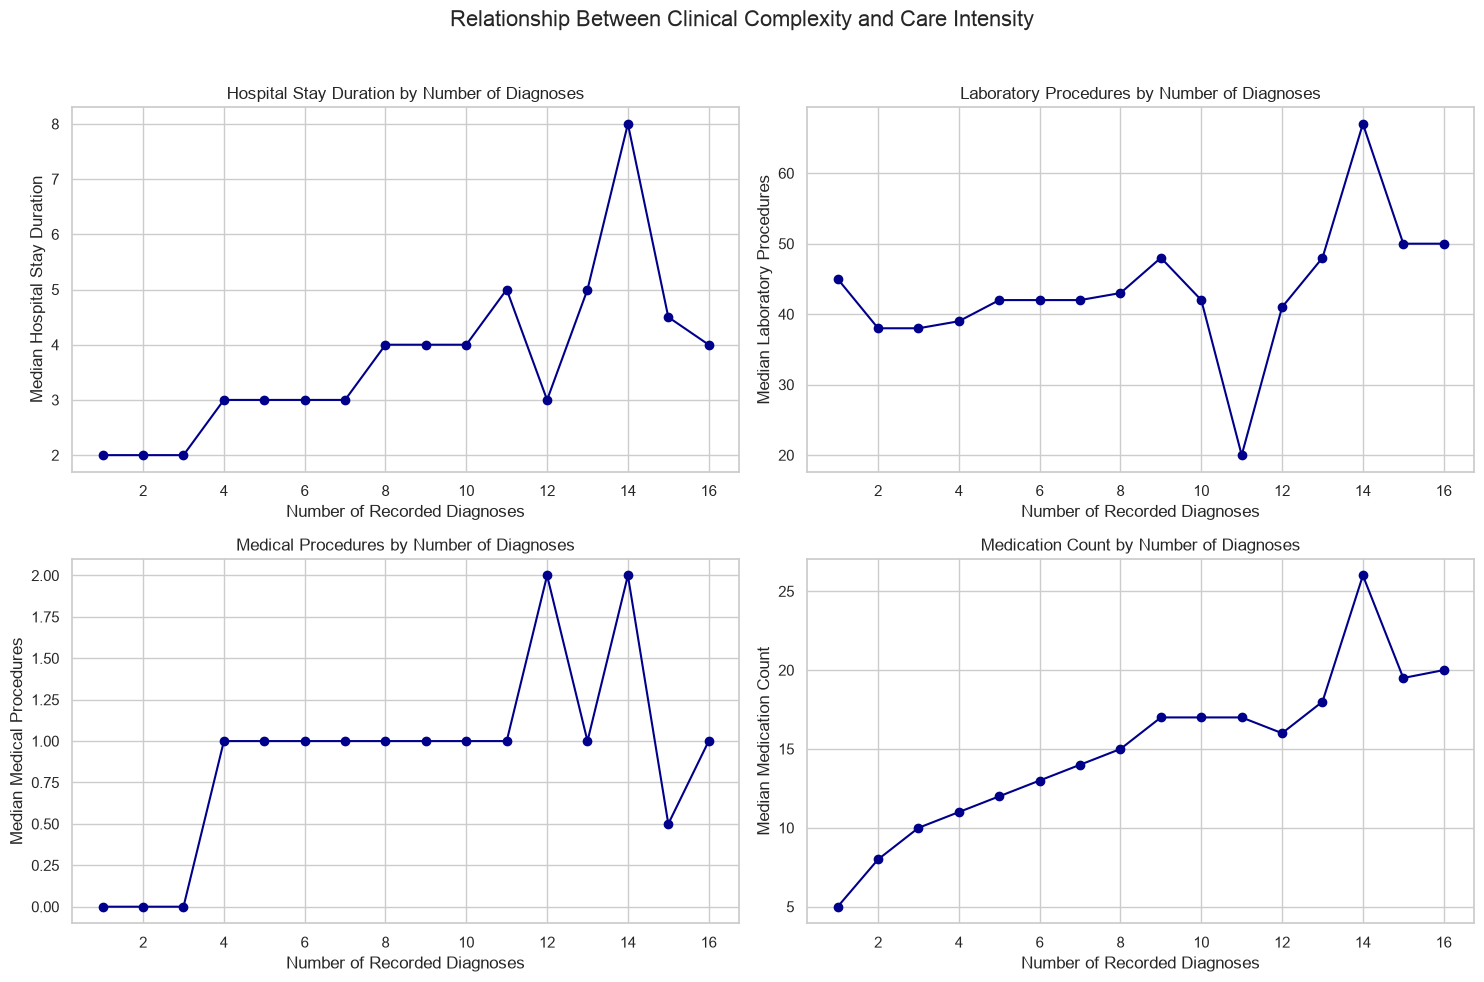

In [24]:
complexity_summary = df.groupby("number_diagnoses")[care_features].median()
display(complexity_summary)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, feature in zip(axes.flat, care_features):
    ax.plot(complexity_summary.index, complexity_summary[feature], marker="o", color="darkblue")
    ax.set_title(f"{care_labels[feature]} by Number of Diagnoses")
    ax.set_xlabel("Number of Recorded Diagnoses")
    ax.set_ylabel(f"Median {care_labels[feature]}")
fig.suptitle("Relationship Between Clinical Complexity and Care Intensity", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 25. Previous inpatient visits and readmission

Group prior-year inpatient visits into 0, 1, 2–3 and 4+. Zero does not mean no lifetime admission history.

,Encounters,Early_Readmissions,Readmission Rate (%)
prior_inpatient_group,,,
0,67630,5706,8.44
1,19521,2523,12.92
2-3,10977,2011,18.32
4+,3638,1117,30.70


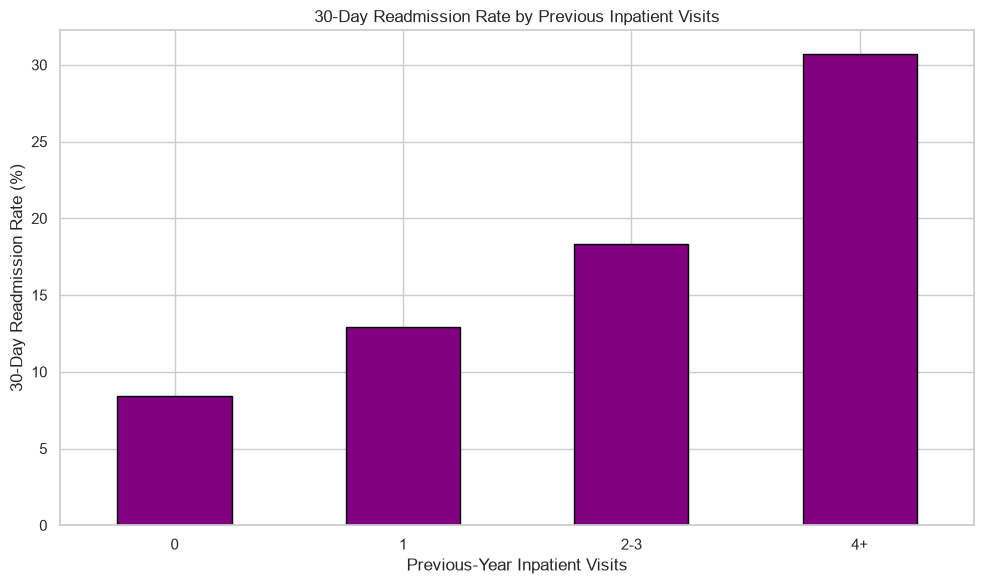

In [25]:
df["prior_inpatient_group"] = pd.cut(df["number_inpatient"], bins=[-1, 0, 1, 3, np.inf], labels=["0", "1", "2-3", "4+"])
prior_readmission = df.groupby("prior_inpatient_group", observed=True)["readmitted_30"].agg(
    Encounters="count", Early_Readmissions="sum", Rate="mean")
prior_readmission["Rate"] *= 100
prior_readmission = prior_readmission.rename(columns={"Rate": "Readmission Rate (%)"})
display(prior_readmission.round(2))
plt.figure(figsize=(10, 6))
prior_readmission["Readmission Rate (%)"].plot(kind="bar", color="purple", edgecolor="black")
plt.title("30-Day Readmission Rate by Previous Inpatient Visits")
plt.xlabel("Previous-Year Inpatient Visits")
plt.ylabel("30-Day Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Phase 6 — Laboratory and medication analysis

### 26. HbA1c and maximum glucose results

Keep the recorded not-tested category (`None`) distinct from missing or unrecorded values.

A1Cresult


A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

max_glu_serum


max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

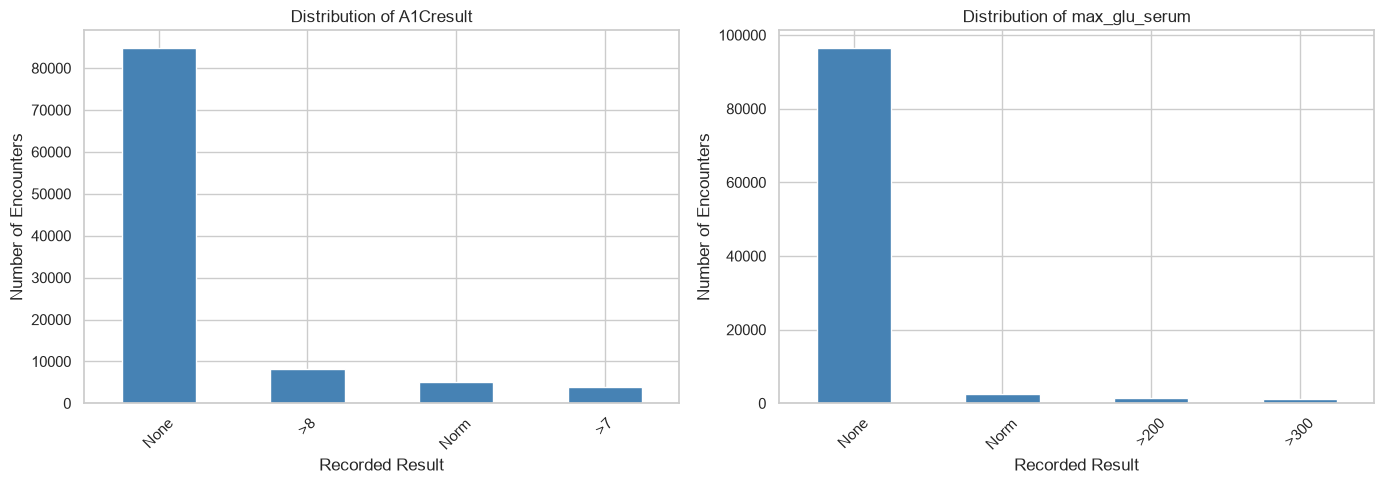

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, feature in zip(axes, ["A1Cresult", "max_glu_serum"]):
    counts = df[feature].fillna("Missing / Unrecorded").value_counts()
    print(feature)
    display(counts)
    counts.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel("Recorded Result")
    ax.set_ylabel("Number of Encounters")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

### 27. Medication changes and readmission

Compare unadjusted readmission proportions by recorded medication change status. This is not a treatment-effect estimate.

,No Early Readmission,Early Readmission
change,,
Ch,88.18,11.82
No,89.41,10.59


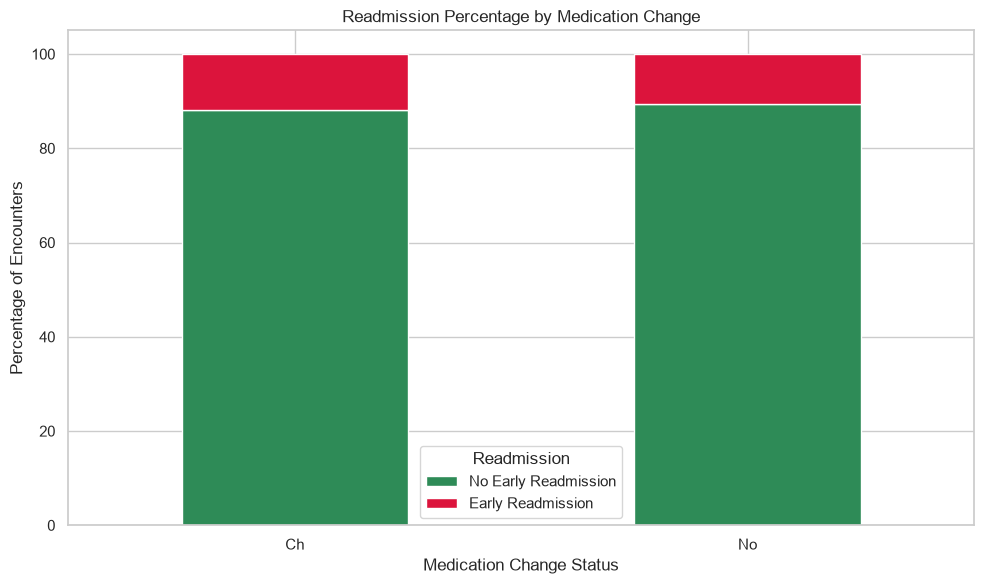

In [27]:
medication_readmission = pd.crosstab(df["change"], df["readmitted_30"], normalize="index").reindex(columns=[0, 1], fill_value=0) * 100
medication_readmission.columns = ["No Early Readmission", "Early Readmission"]
display(medication_readmission.round(2))
medication_readmission.plot(kind="bar", stacked=True, figsize=(10, 6), color=["seagreen", "crimson"])
plt.title("Readmission Percentage by Medication Change")
plt.xlabel("Medication Change Status")
plt.ylabel("Percentage of Encounters")
plt.xticks(rotation=0)
plt.legend(title="Readmission")
plt.tight_layout()
plt.show()

## Phase 7 — Multivariate analysis

### 28. Spearman correlation heatmap

Explore monotonic relationships among care intensity, clinical complexity, utilisation and readmission. Correlations are unadjusted and do not establish causation.

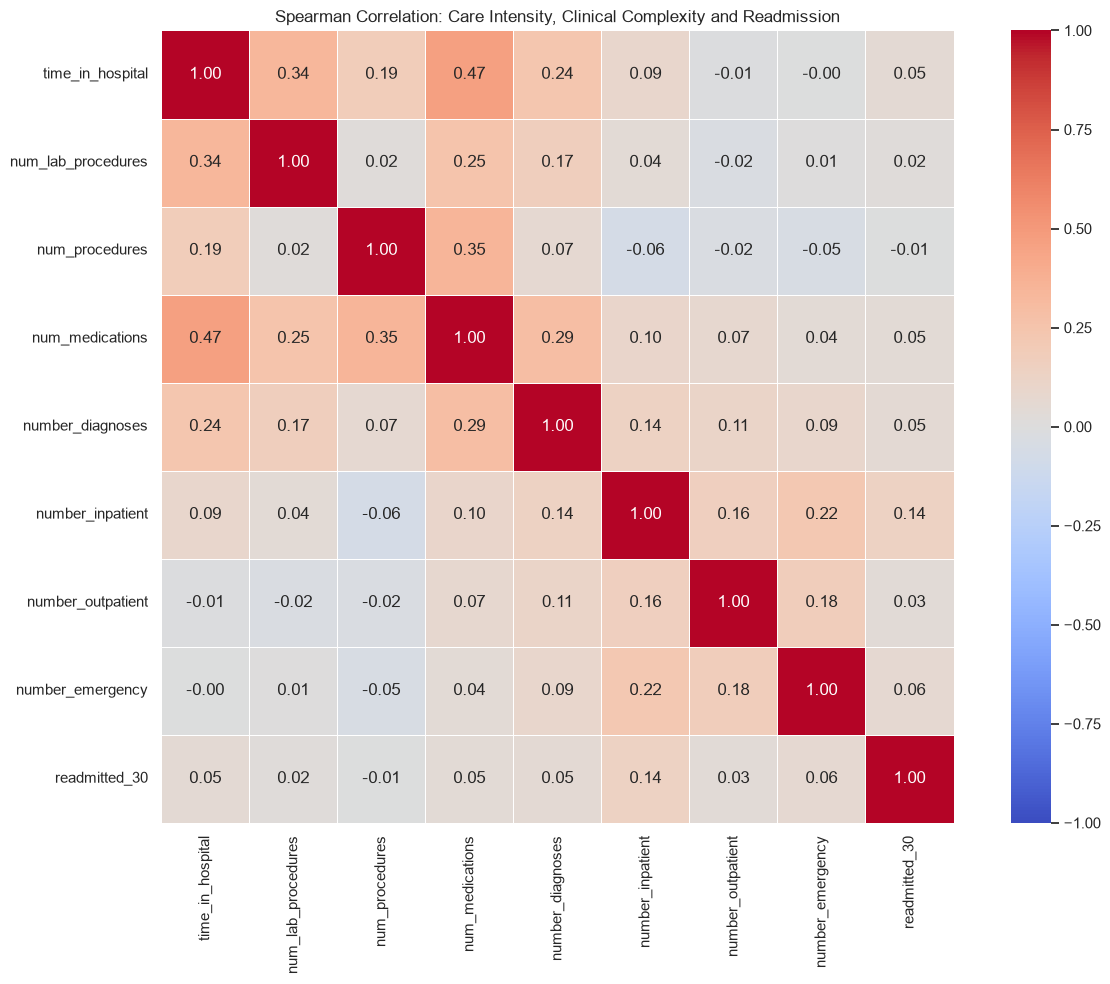

In [28]:
correlation_features = care_features + clinical_features + ["readmitted_30"]
correlation_matrix = df[correlation_features].corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5, square=True)
plt.title("Spearman Correlation: Care Intensity, Clinical Complexity and Readmission")
plt.tight_layout()
plt.show()

### 29. Relationships between care-intensity dimensions

Use a reproducible random sample of up to 3,000 encounters to reduce plotting time. The sample is for visualisation only.

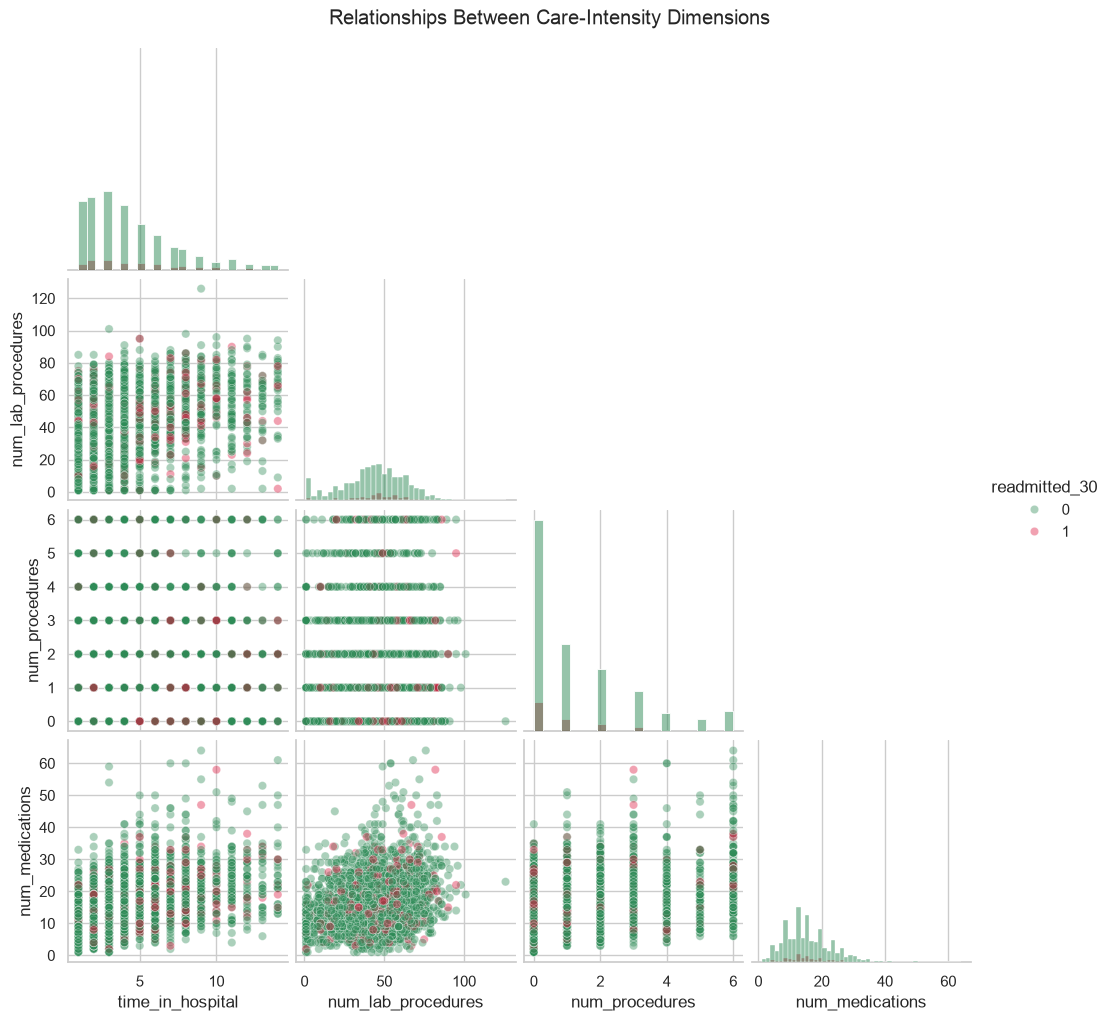

In [29]:
sample_df = df.sample(n=min(3000, len(df)), random_state=42)
plot = sns.pairplot(data=sample_df[care_features + ["readmitted_30"]], hue="readmitted_30",
                   hue_order=[0, 1], palette=["seagreen", "crimson"], diag_kind="hist",
                   corner=True, plot_kws={"alpha": 0.4})
plot.fig.suptitle("Relationships Between Care-Intensity Dimensions", y=1.02)
plt.show()

## EDA findings and next steps

Complete these observations after running the notebook on the actual dataset. Do not invent numerical findings.

| Area | Observation to record |
|---|---|
| Data quality | Dataset size, missing-value patterns, duplicate IDs and repeat encounters |
| Demographics | Representation across age, gender and race; small subgroup sizes |
| Readmission | Positive class prevalence and class imbalance |
| Care intensity | Typical ranges, distribution shapes and unusual values |
| Clinical complexity | How observed care changes with diagnosis counts and prior utilisation |
| RQ1 | Unadjusted care/readmission patterns to investigate using adjusted analysis |
| RQ2 | Candidate features and evaluation metrics; no predictive claim yet |

**Next stage:** `cleaning/` — define the eligible discharge cohort (including how to handle deaths, transfers and other discharge dispositions), preserve patient IDs for grouped splitting, and document missingness and encoding decisions. Fit preprocessing on training data only. Expected-care estimates for training records must be out-of-fold with patient-grouped folds; apply trained models to held-out patients. Use standardised residuals for the four discordance dimensions and compare identical classifier splits across the three agreed feature sets.

Expected care means the statistically typical recorded care conditional on chosen predictors, not medically recommended care. Neither this EDA nor the historical dataset can prove premature discharge, inappropriate treatment or actual cost savings.